# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Maulana Rhys Pradana | 5054251041 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [3]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [ ]:
df = pd.read_csv('Mall_Customers.csv')

print("5 Baris Pertama Dataset")
display(df.head())

print(f"\nJumlah Baris: {df.shape[0]}, Jumlah Kolom: {df.shape[1]}")

print("\nTipe Data dan Informasi Kolom ===")
print(df.info())

print("\nStatistik Deskriptif")
display(df.describe())

print("\n=== Jumlah Missing Value per Kolom ===")
print(df.isnull().sum())

print(f"\nJumlah Baris Duplikat: {df.duplicated().sum()}")

5 Baris Pertama Dataset


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Jumlah Baris: 200, Jumlah Kolom: 5

Tipe Data dan Informasi Kolom ===
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
None

Statistik Deskriptif


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



=== Jumlah Missing Value per Kolom ===
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah Baris Duplikat: 0


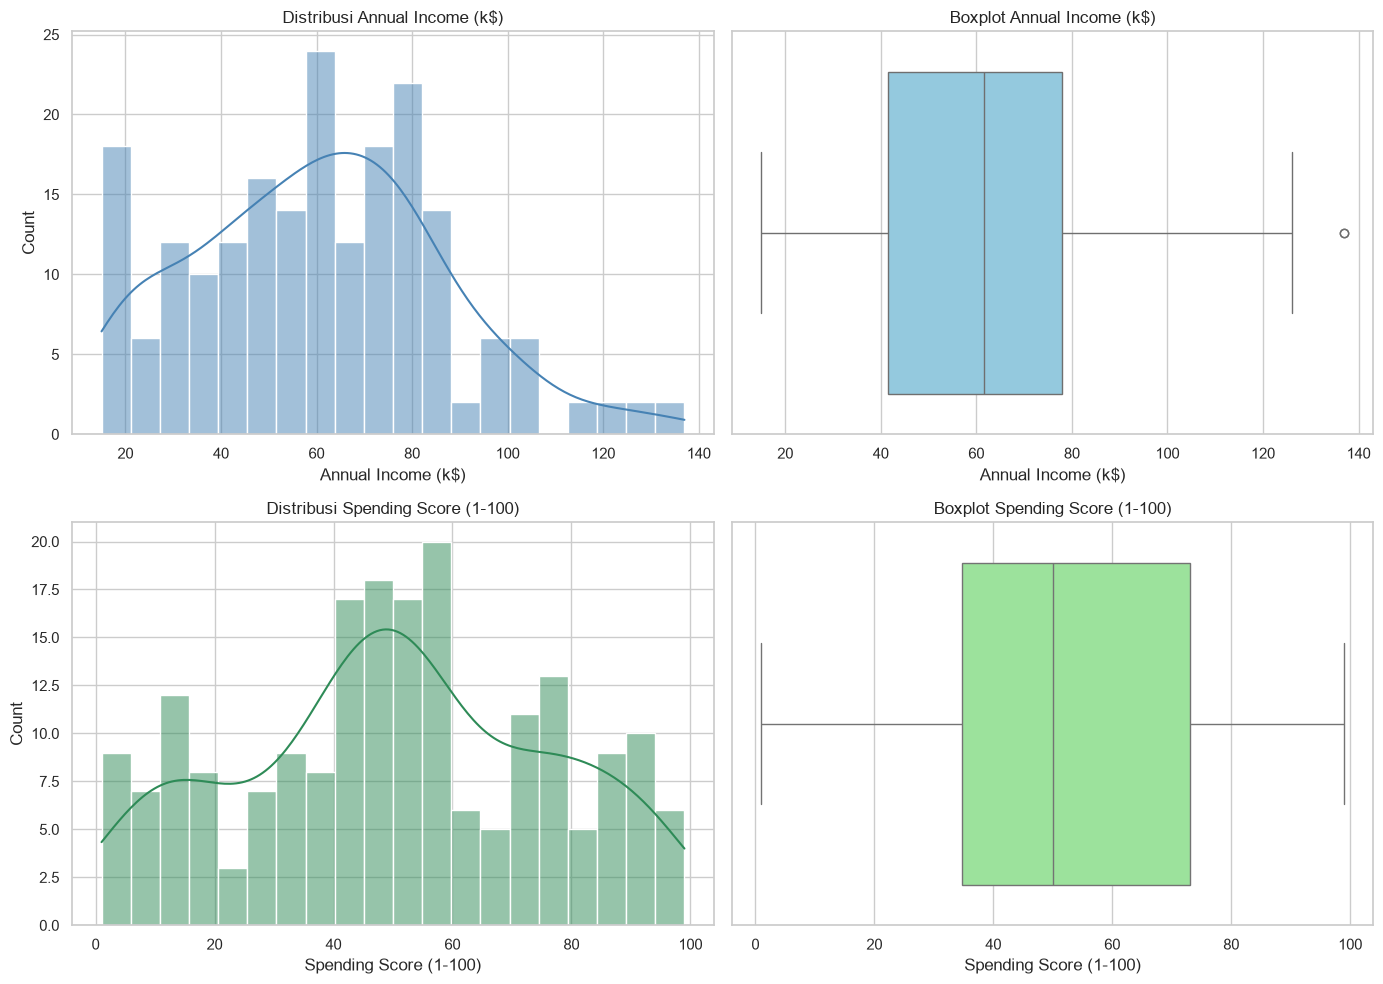

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['Annual Income (k$)'], kde=True, ax=axes[0, 0], color='steelblue', bins=20)
axes[0, 0].set_title('Distribusi Annual Income (k$)')

sns.boxplot(x=df['Annual Income (k$)'], ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('Boxplot Annual Income (k$)')

sns.histplot(df['Spending Score (1-100)'], kde=True, ax=axes[1, 0], color='seagreen', bins=20)
axes[1, 0].set_title('Distribusi Spending Score (1-100)')

sns.boxplot(x=df['Spending Score (1-100)'], ax=axes[1, 1], color='lightgreen')
axes[1, 1].set_title('Boxplot Spending Score (1-100)')

plt.tight_layout()
plt.show()

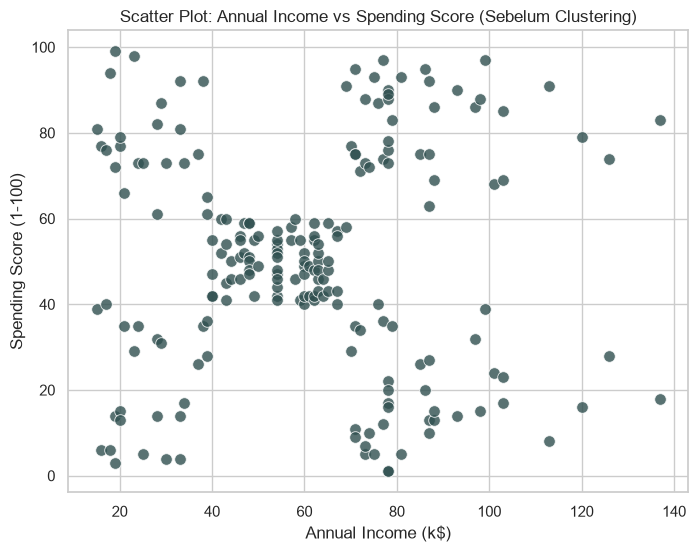

In [6]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    s=70, 
    color='darkslategray', 
    alpha=0.8
)
plt.title('Scatter Plot: Annual Income vs Spending Score (Sebelum Clustering)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

**Jawaban Pertanyaan EDA:**
* **Missing value dan duplikat:** Tidak ditemukan *missing value* (`0` pada seluruh kolom) dan tidak ada baris duplikat (`0` duplikat) dari total 200 baris dan 5 kolom data.
* **Rentang nilai fitur:**
  * `Annual Income (k$)` memiliki rentang antara **15 k$ hingga 137 k$**, dengan rata-rata **60.56 k$** dan median **61.50 k$**. Distribusinya sedikit condong ke kanan (*right-skewed*) dan pada boxplot terlihat terdapat titik ekstrim (*outlier*) di ujung atas yaitu pada pendapatan **137 k$**.
  * `Spending Score (1-100)` memiliki rentang antara **1 hingga 99**, dengan rata-rata **50.20** dan median **50.00**. Distribusinya relatif simetris dan terkonsentrasi di sekitar nilai tengah (40–60) tanpa adanya *outlier* pada boxplot.
* **Pola kelompok pada Scatter Plot:** Ya, secara visual terlihat sangat jelas adanya **5 kelompok (cluster)** yang terpisah:
  1. Pendapatan rendah, pengeluaran rendah (kiri bawah).
  2. Pendapatan rendah, pengeluaran tinggi (kiri atas).
  3. Pendapatan menengah, pengeluaran menengah (kelompok paling padat di bagian tengah).
  4. Pendapatan tinggi, pengeluaran rendah (kanan bawah).
  5. Pendapatan tinggi, pengeluaran tinggi (kanan atas).

# 2. Preprocessing

In [ ]:
df_clean = df.dropna().drop_duplicates().copy()

features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df_clean[features].copy()

print("Dimensi fitur X:", X.shape)
display(X.head())

Dimensi fitur X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [ ]:
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled_array, columns=features, index=X.index)

print("=== 5 Baris Pertama X_scaled ===")
display(X_scaled.head())

print("\n=== Statistik Deskriptif X_scaled ===")
display(X_scaled.describe().round(4))

=== 5 Baris Pertama X_scaled ===


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



=== Statistik Deskriptif X_scaled ===


,Annual Income (k$),Spending Score (1-100)
count,200.0000,200.0000
mean,-0.0000,-0.0000
std,1.0025,1.0025
min,-1.7390,-1.9100
25%,-0.7275,-0.5998
50%,0.0359,-0.0078
75%,0.6657,0.8851
max,2.9177,1.8945


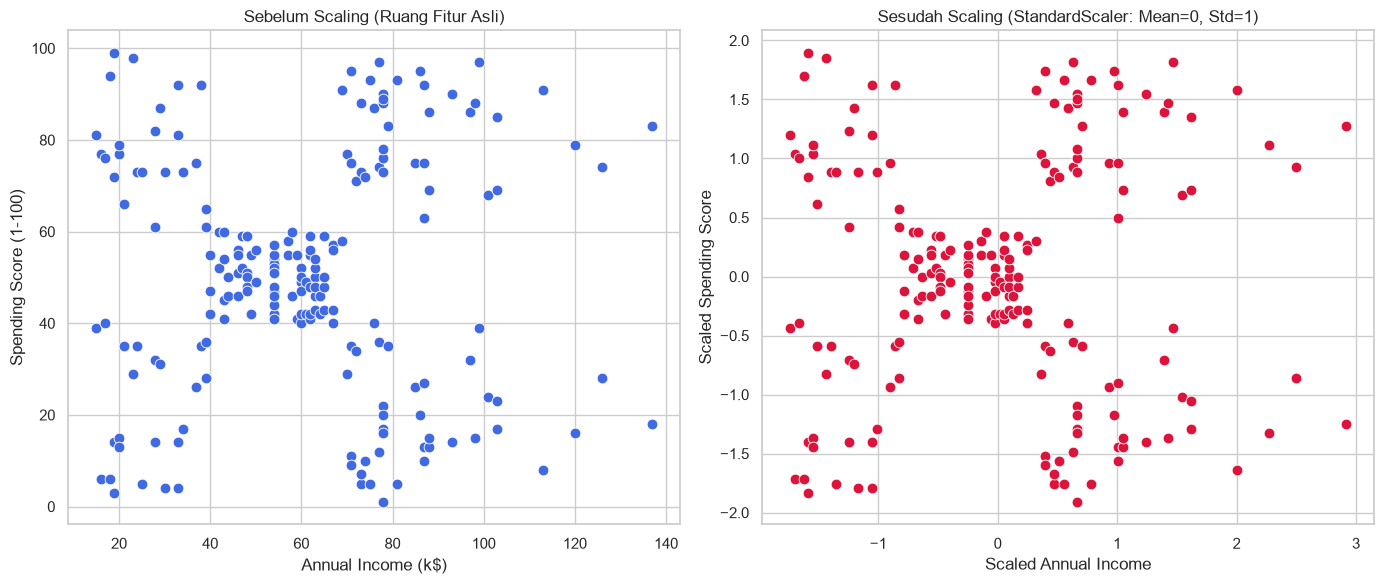

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(data=X, x='Annual Income (k$)', y='Spending Score (1-100)', ax=axes[0], color='royalblue', s=60)
axes[0].set_title('Sebelum Scaling (Ruang Fitur Asli)')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')

sns.scatterplot(data=X_scaled, x='Annual Income (k$)', y='Spending Score (1-100)', ax=axes[1], color='crimson', s=60)
axes[1].set_title('Sesudah Scaling (StandardScaler: Mean=0, Std=1)')
axes[1].set_xlabel('Scaled Annual Income')
axes[1].set_ylabel('Scaled Spending Score')

plt.tight_layout()
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Penjelasan Pemilihan Fitur & Pentingnya Scaling:**
* **Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.
* **Alasan pemilihan:** Kedua fitur numerik ini secara langsung merepresentasikan kapasitas finansial dan perilaku belanja (*spending habit*) aktual pelanggan, sehingga sangat ideal untuk segmentasi daya beli. `CustomerID` **tidak digunakan** karena hanya berupa nomor urut identitas unik (1 hingga 200) yang tidak memiliki makna matematis atau perilaku; memasukkannya hanya akan mendistorsi jarak (*distance*) antar pelanggan.
* **Mengapa *Feature Scaling* penting:** Kedua fitur awalnya memiliki skala variansi yang sedikit berbeda (simpangan baku pendapatan **26.26** vs skor pengeluaran **25.82**). Algoritma klastering seperti DBSCAN (menggunakan parameter jarak `eps`) sangat sensitif terhadap skala fitur. Melalui `StandardScaler`, kedua fitur kini memiliki rata-rata **0** dan simpangan baku **1**, sehingga jarak ketetanggaan dapat dihitung secara proporsional ke segala arah dimensi.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [ ]:
dbscan_init = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan_init.fit_predict(X_scaled)

print("10 Label pertama hasil DBSCAN (eps=0.3, min_samples=5):")
print(labels_dbscan[:10])

10 Label pertama hasil DBSCAN (eps=0.3, min_samples=5):
[ 2  0  1  0  2  0  1 -1  1  0]


In [11]:
label_counts_db = pd.Series(labels_dbscan).value_counts().sort_index()
print("=== Jumlah Anggota Setiap Label DBSCAN (eps=0.3, min_samples=5) ===")
for label, count in label_counts_db.items():
    nama = "Noise (-1)" if label == -1 else f"Cluster {label}"
    print(f"{nama:12s}: {count} pelanggan")

n_clusters_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_db = int(np.sum(labels_dbscan == -1))

print(f"\nTotal Cluster Terbentuk (tanpa noise): {n_clusters_db}")
print(f"Total Titik Noise (label -1)         : {n_noise_db} ({n_noise_db/len(X)*100:.1f}%)")

=== Jumlah Anggota Setiap Label DBSCAN (eps=0.3, min_samples=5) ===
Noise (-1)  : 35 pelanggan
Cluster 0   : 12 pelanggan
Cluster 1   : 5 pelanggan
Cluster 2   : 7 pelanggan
Cluster 3   : 88 pelanggan
Cluster 4   : 30 pelanggan
Cluster 5   : 14 pelanggan
Cluster 6   : 9 pelanggan

Total Cluster Terbentuk (tanpa noise): 7
Total Titik Noise (label -1)         : 35 (17.5%)


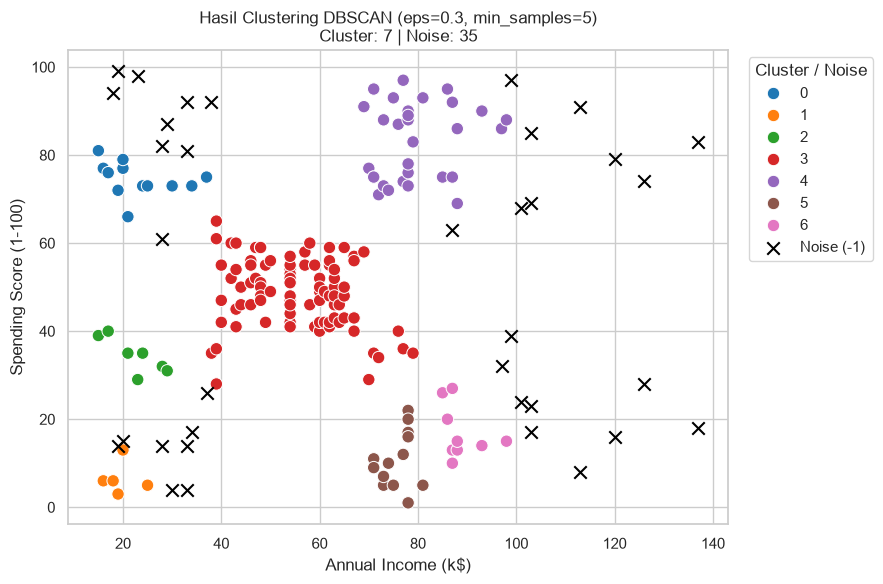

In [ ]:
plt.figure(figsize=(9, 6))

mask_noise = (labels_dbscan == -1)

sns.scatterplot(
    x=X.loc[~mask_noise, 'Annual Income (k$)'],
    y=X.loc[~mask_noise, 'Spending Score (1-100)'],
    hue=labels_dbscan[~mask_noise],
    palette='tab10',
    s=80,
    legend='full'
)

plt.scatter(
    X.loc[mask_noise, 'Annual Income (k$)'],
    X.loc[mask_noise, 'Spending Score (1-100)'],
    color='black',
    marker='x',
    s=80,
    label='Noise (-1)'
)

plt.title(f'Hasil Clustering DBSCAN (eps=0.3, min_samples=5)\nCluster: {n_clusters_db} | Noise: {n_noise_db}')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Cluster / Noise')
plt.tight_layout()
plt.show()

In [ ]:
eps_values = [0.2, 0.25, 0.3, 0.35, 0.38, 0.4, 0.5]
min_samples_values = [3, 4, 5, 7, 10]

dbscan_records = []

for eps in eps_values:
    for ms in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=ms)
        lbls = model.fit_predict(X_scaled)
        
        mask_valid = lbls != -1
        n_cl = len(set(lbls[mask_valid]))
        n_ns = int(np.sum(lbls == -1))

        if 2 <= n_cl < np.sum(mask_valid):
            sil_non_noise = round(silhouette_score(X_scaled[mask_valid], lbls[mask_valid]), 4)
        else:
            sil_non_noise = np.nan
            
        dbscan_records.append({
            'eps': eps,
            'min_samples': ms,
            'Jumlah Cluster (tanpa noise)': n_cl,
            'Jumlah Noise': n_ns,
            'Silhouette Score (Non-Noise)': sil_non_noise
        })

df_dbscan_summary = pd.DataFrame(dbscan_records)
display(df_dbscan_summary)

dbscan_best = DBSCAN(eps=0.38, min_samples=7)
labels_dbscan_best = dbscan_best.fit_predict(X_scaled)

,eps,min_samples,Jumlah Cluster (tanpa noise),Jumlah Noise,Silhouette Score (Non-Noise)
0,0.20,3,13,44,0.4697
1,0.20,4,5,73,0.6173
2,0.20,5,7,77,0.5856
3,0.20,7,4,100,0.6094
4,0.20,10,1,129,NaN
5,0.25,3,12,16,0.4090
6,0.25,4,7,43,0.5380
7,0.25,5,6,50,0.5317
8,0.25,7,5,77,0.5945
9,0.25,10,2,111,0.7287


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Jawaban Analisis DBSCAN:**
* **Pengaruh kenaikan `eps`:** Semakin besar `eps`, jangkauan radius pencarian tetangga semakin luas, sehingga jumlah titik *noise* menurun drastis. Contoh dari eksperimen: saat `eps` naik dari `0.20` ke `0.50` (dengan `min_samples=5`), jumlah *noise* turun drastis dari **77 menjadi 8 titik**. Namun, nilai `eps` yang terlalu besar (`0.50`) menyebabkan beberapa cluster berbeda bergabung menjadi hanya **2 cluster** raksasa.
* **Pengaruh `min_samples`:** Semakin besar `min_samples`, syarat pembentukan kelompok menjadi semakin ketat. Contoh: pada `eps=0.20`, menaikkan `min_samples` ke **10** membuat 129 dari 200 titik menjadi *noise*, dan hanya menyisakan 1 cluster di bagian tengah.
* **Kombinasi parameter optimal:** Kombinasi yang paling stabil untuk memetakan kelima kelompok alami tanpa membuang terlalu banyak data adalah **`eps=0.35` hingga `0.38` dengan `min_samples=7`**, yang berhasil membentuk **5 cluster** dengan jumlah *noise* sekitar **23 hingga 47 titik** dan *Silhouette Score* sebesar **0.54 - 0.57**.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [ ]:
birch_init = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch_init.fit_predict(X_scaled)

print("10 Label pertama hasil BIRCH (threshold=0.5, n_clusters=5):")
print(labels_birch[:10])

10 Label pertama hasil BIRCH (threshold=0.5, n_clusters=5):
[3 4 3 4 3 4 3 4 3 4]


In [15]:
birch_counts = pd.Series(labels_birch).value_counts().sort_index()
print("=== Jumlah Anggota Setiap Cluster BIRCH (threshold=0.5, n_clusters=5) ===")
for cl, cnt in birch_counts.items():
    print(f"Cluster {cl}: {cnt} pelanggan")

print(f"\nJumlah Cluster Terbentuk: {len(birch_counts)}")

=== Jumlah Anggota Setiap Cluster BIRCH (threshold=0.5, n_clusters=5) ===
Cluster 0: 36 pelanggan
Cluster 1: 109 pelanggan
Cluster 2: 8 pelanggan
Cluster 3: 25 pelanggan
Cluster 4: 22 pelanggan

Jumlah Cluster Terbentuk: 5


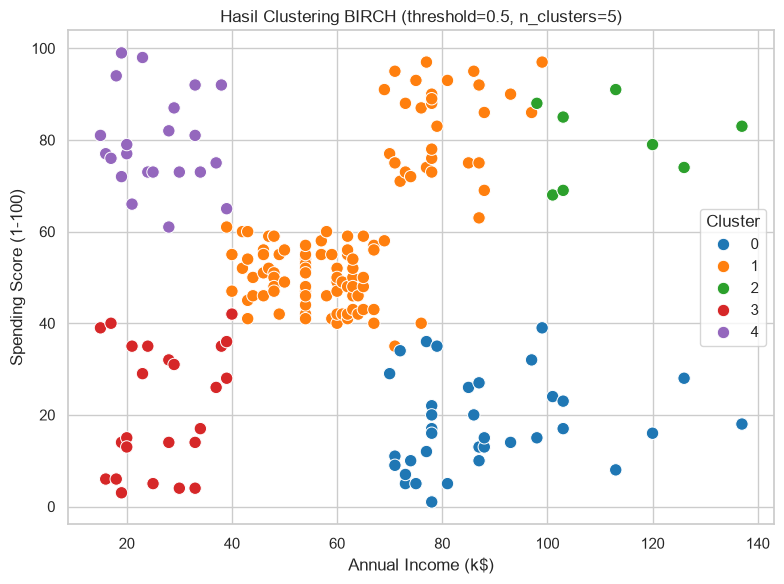

In [16]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X['Annual Income (k$)'],
    y=X['Spending Score (1-100)'],
    hue=labels_birch,
    palette='tab10',
    s=80,
    legend='full'
)
plt.title('Hasil Clustering BIRCH (threshold=0.5, n_clusters=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

In [ ]:
thresholds = [0.2, 0.3, 0.5, 0.7, 1.0]
birch_records = []

for n_cl_param in [5, None]:
    for th in thresholds:
        model_b = Birch(threshold=th, n_clusters=n_cl_param)
        lbls_b = model_b.fit_predict(X_scaled)
        actual_k = len(set(lbls_b))
        
        if 2 <= actual_k < len(X_scaled):
            sil_b = round(silhouette_score(X_scaled, lbls_b), 4)
        else:
            sil_b = np.nan
            
        birch_records.append({
            'threshold': th,
            'n_clusters (parameter)': str(n_cl_param),
            'Jumlah Cluster Terbentuk': actual_k,
            'Silhouette Score': sil_b
        })

df_birch_summary = pd.DataFrame(birch_records)
display(df_birch_summary)

birch_best = Birch(threshold=0.2, n_clusters=5)
labels_birch_best = birch_best.fit_predict(X_scaled)

,threshold,n_clusters (parameter),Jumlah Cluster Terbentuk,Silhouette Score
0,0.2,5,5,0.5538
1,0.3,5,5,0.4781
2,0.5,5,5,0.4145
3,0.7,5,5,0.4207
4,1.0,5,4,0.3886
5,0.2,None,39,0.4014
6,0.3,None,23,0.4143
7,0.5,None,10,0.4774
8,0.7,None,6,0.4861
9,1.0,None,4,0.3886


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Jawaban Analisis BIRCH:**
* **Pengaruh `threshold`:** Ketika `threshold` (radius subcluster) diperbesar, satu daun (*leaf*) di *CF-Tree* menelan radius yang lebih lebar, sehingga jumlah subcluster awal menyusut drastis. Berdasarkan eksperimen (dengan parameter `n_clusters=None`), menaikkan `threshold` dari **0.2 -> 0.3 -> 0.5 -> 0.7 -> 1.0** membuat jumlah subcluster daun turun berturut-turut dari **39 -> 23 -> 10 -> 6 -> 4**.
* **Perbedaan dengan DBSCAN:** BIRCH **tidak mendeteksi *noise*** secara eksplisit (tidak ada label `-1`). Semua titik pinggiran yang jauh tetap akan digabungkan ke dalam *subcluster* terdekat di pohon CF.
* **Pengaruh `n_clusters`:** Menentukan `n_clusters=5` memaksa BIRCH melakukan *agglomerative clustering* pada tahap akhir. Kualitas klaster sangat dipengaruhi oleh `threshold`: BIRCH dengan `threshold=0.2, n_clusters=5` menghasilkan *Silhouette Score* tinggi (**0.5538**) karena 39 subcluster halusnya dirangkum dengan rapi, dibandingkan `threshold=0.5, n_clusters=5` yang memiliki *Silhouette Score* rendah (**0.4145**) akibat batas subcluster awalnya terlalu kasar.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [18]:
gmm_init = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
gmm_init.fit(X_scaled)
labels_gmm = gmm_init.predict(X_scaled)

print("10 Label pertama hasil GMM (n_components=5):")
print(labels_gmm[:10])

10 Label pertama hasil GMM (n_components=5):
[4 2 4 2 4 2 4 2 4 2]


In [ ]:
gmm_counts = pd.Series(labels_gmm).value_counts().sort_index()
print("=== Jumlah Anggota Setiap Cluster GMM (n_components=5) ===")
for cl, cnt in gmm_counts.items():
    print(f"Cluster {cl}: {cnt} pelanggan")

proba_gmm = gmm_init.predict_proba(X_scaled)
df_proba = pd.DataFrame(proba_gmm, columns=[f'Prob_Cluster_{i}' for i in range(5)])
df_proba['Max_Probability'] = df_proba.max(axis=1)
df_proba['Assigned_Cluster'] = labels_gmm
df_proba['Annual Income (k$)'] = X['Annual Income (k$)'].values
df_proba['Spending Score (1-100)'] = X['Spending Score (1-100)'].values

print("\n=== 5 Baris Pertama Probabilitas Keanggotaan GMM ===")
display(df_proba.head().round(4))

print("\n=== Titik Pelanggan dengan Keanggotaan Paling Tidak Pasti (Max Probability < 0.70) ===")
uncertain_points = df_proba[df_proba['Max_Probability'] < 0.70].sort_values(by='Max_Probability')
display(uncertain_points.round(4))

=== Jumlah Anggota Setiap Cluster GMM (n_components=5) ===
Cluster 0: 84 pelanggan
Cluster 1: 39 pelanggan
Cluster 2: 21 pelanggan
Cluster 3: 33 pelanggan
Cluster 4: 23 pelanggan

=== 5 Baris Pertama Probabilitas Keanggotaan GMM ===


,Prob_Cluster_0,Prob_Cluster_1,Prob_Cluster_2,Prob_Cluster_3,Prob_Cluster_4,Max_Probability,Assigned_Cluster,Annual Income (k$),Spending Score (1-100)
0,0.0000,0.0000,0.0010,0.0000,0.9990,0.9990,4,15,39
1,0.0000,0.0002,0.9998,0.0000,0.0000,0.9998,2,15,81
2,0.0000,0.0000,0.0000,0.0002,0.9998,0.9998,4,16,6
3,0.0001,0.0002,0.9997,0.0000,0.0000,0.9997,2,16,77
4,0.0001,0.0000,0.0016,0.0000,0.9984,0.9984,4,17,40



=== Titik Pelanggan dengan Keanggotaan Paling Tidak Pasti (Max Probability < 0.70) ===


,Prob_Cluster_0,Prob_Cluster_1,Prob_Cluster_2,Prob_Cluster_3,Prob_Cluster_4,Max_Probability,Assigned_Cluster,Annual Income (k$),Spending Score (1-100)
124,0.4971,0.0000,0.0000,0.5029,0.0000,0.5029,3,70,29
48,0.6114,0.0000,0.0003,0.0000,0.3883,0.6114,0,40,42
49,0.6114,0.0000,0.0003,0.0000,0.3883,0.6114,0,40,42
27,0.2785,0.0005,0.6746,0.0000,0.0464,0.6746,2,28,61


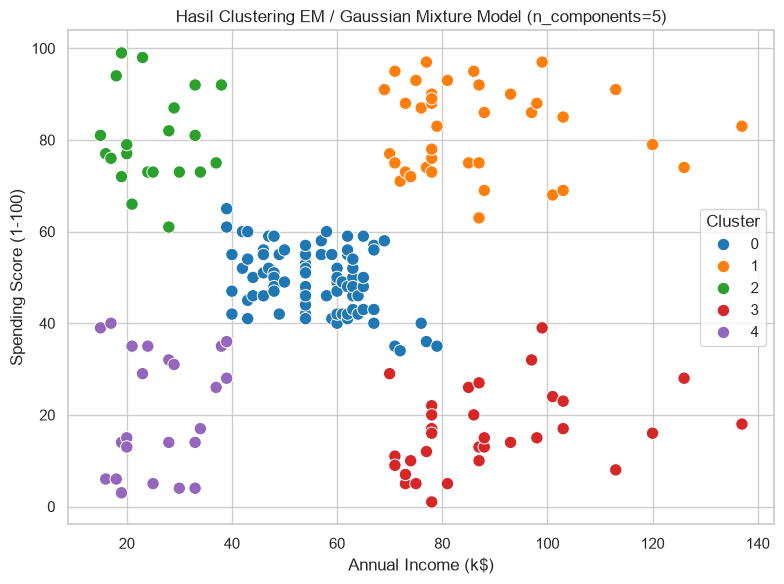

In [20]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X['Annual Income (k$)'],
    y=X['Spending Score (1-100)'],
    hue=labels_gmm,
    palette='tab10',
    s=80,
    legend='full'
)
plt.title('Hasil Clustering EM / Gaussian Mixture Model (n_components=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

,n_components,Silhouette Score,BIC,AIC
0,2,0.3791,1153.9047,1117.6232
1,3,0.4302,1151.7183,1095.6469
2,4,0.4134,1103.7901,1027.9288
3,5,0.5537,1058.6523,963.0010
4,6,0.5170,1074.6828,959.2417
5,7,0.5091,1087.3285,952.0975
6,8,0.4302,1102.3707,947.3498


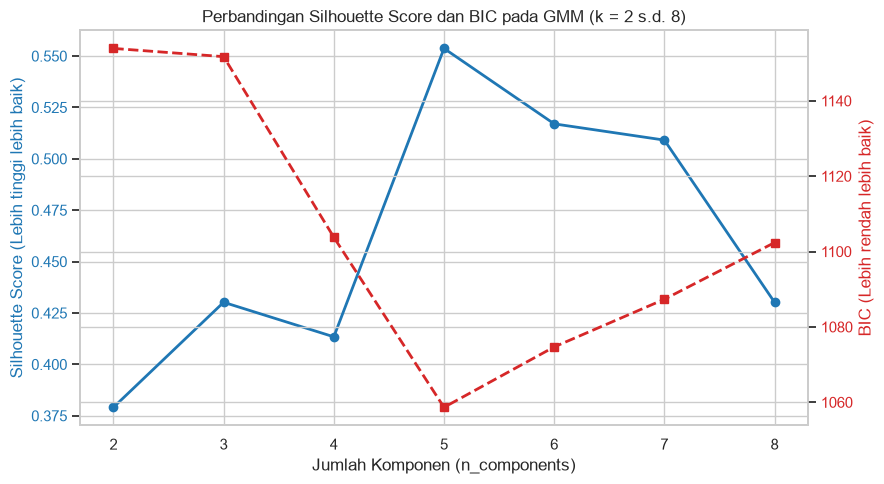

In [ ]:
n_components_range = range(2, 9)
gmm_records = []

for k in n_components_range:
    gmm_k = GaussianMixture(n_components=k, covariance_type='full', random_state=42)
    gmm_k.fit(X_scaled)
    lbls_k = gmm_k.predict(X_scaled)
    
    sil_k = silhouette_score(X_scaled, lbls_k)
    bic_k = gmm_k.bic(X_scaled)
    aic_k = gmm_k.aic(X_scaled)
    
    gmm_records.append({
        'n_components': k,
        'Silhouette Score': round(sil_k, 4),
        'BIC': round(bic_k, 4),
        'AIC': round(aic_k, 4)
    })

df_gmm_summary = pd.DataFrame(gmm_records)
display(df_gmm_summary)

fig, ax1 = plt.subplots(figsize=(9, 5))

color1 = 'tab:blue'
ax1.set_xlabel('Jumlah Komponen (n_components)')
ax1.set_ylabel('Silhouette Score (Lebih tinggi lebih baik)', color=color1)
ax1.plot(df_gmm_summary['n_components'], df_gmm_summary['Silhouette Score'], marker='o', color=color1, linewidth=2, label='Silhouette Score')
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
color2 = 'tab:red'
ax2.set_ylabel('BIC (Lebih rendah lebih baik)', color=color2)
ax2.plot(df_gmm_summary['n_components'], df_gmm_summary['BIC'], marker='s', linestyle='--', color=color2, linewidth=2, label='BIC')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Perbandingan Silhouette Score dan BIC pada GMM (k = 2 s.d. 8)')
plt.tight_layout()
plt.show()

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Jawaban Analisis EM/GMM:**
* **Arti probabilitas keanggotaan pada GMM:** Berbeda dengan *hard clustering* yang langsung memaksa satu titik masuk secara mutlak ke satu cluster, GMM melakukan *soft clustering*. Nilai probabilitas (melalui `predict_proba`) menunjukkan peluang posterior bahwa suatu titik sampel dibangkitkan oleh masing-masing distribusi Gaussian ke-$k$. Contohnya, sebagian besar pelanggan memiliki probabilitas $>0.99$ pada satu cluster, tetapi pelanggan pada batas antar cluster memiliki probabilitas yang terbagi (misal 50% di Cluster A dan 50% di Cluster B).
* **Apa yang terjadi ketika `n_components` diubah:**
  * Jika `n_components` terlalu kecil (misalnya 2, 3, atau 4), beberapa kelompok pelanggan yang sebenarnya terpisah dipaksa bergabung ke dalam satu distribusi elips Gaussian yang lebar, sehingga *Silhouette Score* rendah dan nilai BIC tinggi.
  * Jika `n_components` terlalu besar (misalnya 6, 7, atau 8), kelompok alami yang padat terpecah-pecah (*over-segmentation*) dan model terkena penalti kompleksitas parameter, sehingga nilai BIC kembali naik dan *Silhouette Score* turun.
* **Mengapa jumlah cluster GMM perlu ditentukan sebelum dilatih:** Algoritma *Expectation-Maximization* (EM) membutuhkan inisialisasi sejumlah $K$ parameter distribusi Gaussian (vektor rata-rata $\mu$, matriks kovarians $\Sigma$, dan bobot campuran $\pi$) sejak awal iterasi untuk dapat menghitung tahap *Expectation* (E-step) dan *Maximization* (M-step).
* **Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?** **Ya, tepat sama.** Pada eksperimen ini, **`n_components = 5`** secara konsisten menghasilkan **Silhouette Score tertinggi** sekaligus **nilai BIC terendah**. Hal ini mengonfirmasi secara geometris maupun probabilistik bahwa 5 komponen adalah jumlah cluster paling optimal.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [ ]:
def evaluate_clustering_model(X_data, labels, model_name="Model"):
    """
    Mengevaluasi hasil clustering menggunakan Silhouette, Davies-Bouldin, dan Calinski-Harabasz.
    Untuk DBSCAN (atau model dengan label -1), metrik dihitung pada titik non-noise saja.
    """
    labels = np.array(labels)
    mask_non_noise = (labels != -1)
    
    n_noise = int(np.sum(labels == -1))
    valid_X = X_data[mask_non_noise]
    valid_labels = labels[mask_non_noise]
    
    n_clusters = len(set(valid_labels))

    if 2 <= n_clusters < len(valid_X):
        sil = round(silhouette_score(valid_X, valid_labels), 4)
        dbi = round(davies_bouldin_score(valid_X, valid_labels), 4)
        chi = round(calinski_harabasz_score(valid_X, valid_labels), 4)
    else:
        sil, dbi, chi = np.nan, np.nan, np.nan
        
    return {
        'Model': model_name,
        'Jumlah Cluster': n_clusters,
        'Jumlah Noise': n_noise,
        'Silhouette Score': sil,
        'Davies-Bouldin Index': dbi,
        'Calinski-Harabasz Score': chi
    }

In [ ]:
eval_results = [
    evaluate_clustering_model(X_scaled, labels_dbscan, "DBSCAN Awal (eps=0.3, min_samples=5)"),
    evaluate_clustering_model(X_scaled, labels_dbscan_best, "DBSCAN Terbaik (eps=0.38, min_samples=7)"),
    evaluate_clustering_model(X_scaled, labels_birch, "BIRCH Awal (threshold=0.5, n_clusters=5)"),
    evaluate_clustering_model(X_scaled, labels_birch_best, "BIRCH Terbaik (threshold=0.2, n_clusters=5)"),
    evaluate_clustering_model(X_scaled, labels_gmm, "GMM / EM Terbaik (n_components=5, full)")
]

df_comparison = pd.DataFrame(eval_results)
display(df_comparison)

,Model,Jumlah Cluster,Jumlah Noise,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,"DBSCAN Awal (eps=0.3, min_samples=5)",7,35,0.5243,0.5800,185.5758
1,"DBSCAN Terbaik (eps=0.38, min_samples=7)",5,23,0.5416,0.5117,213.5550
2,"BIRCH Awal (threshold=0.5, n_clusters=5)",5,0,0.4145,0.6979,125.9486
3,"BIRCH Terbaik (threshold=0.2, n_clusters=5)",5,0,0.5538,0.5779,244.4103
4,"GMM / EM Terbaik (n_components=5, full)",5,0,0.5537,0.5760,244.9402


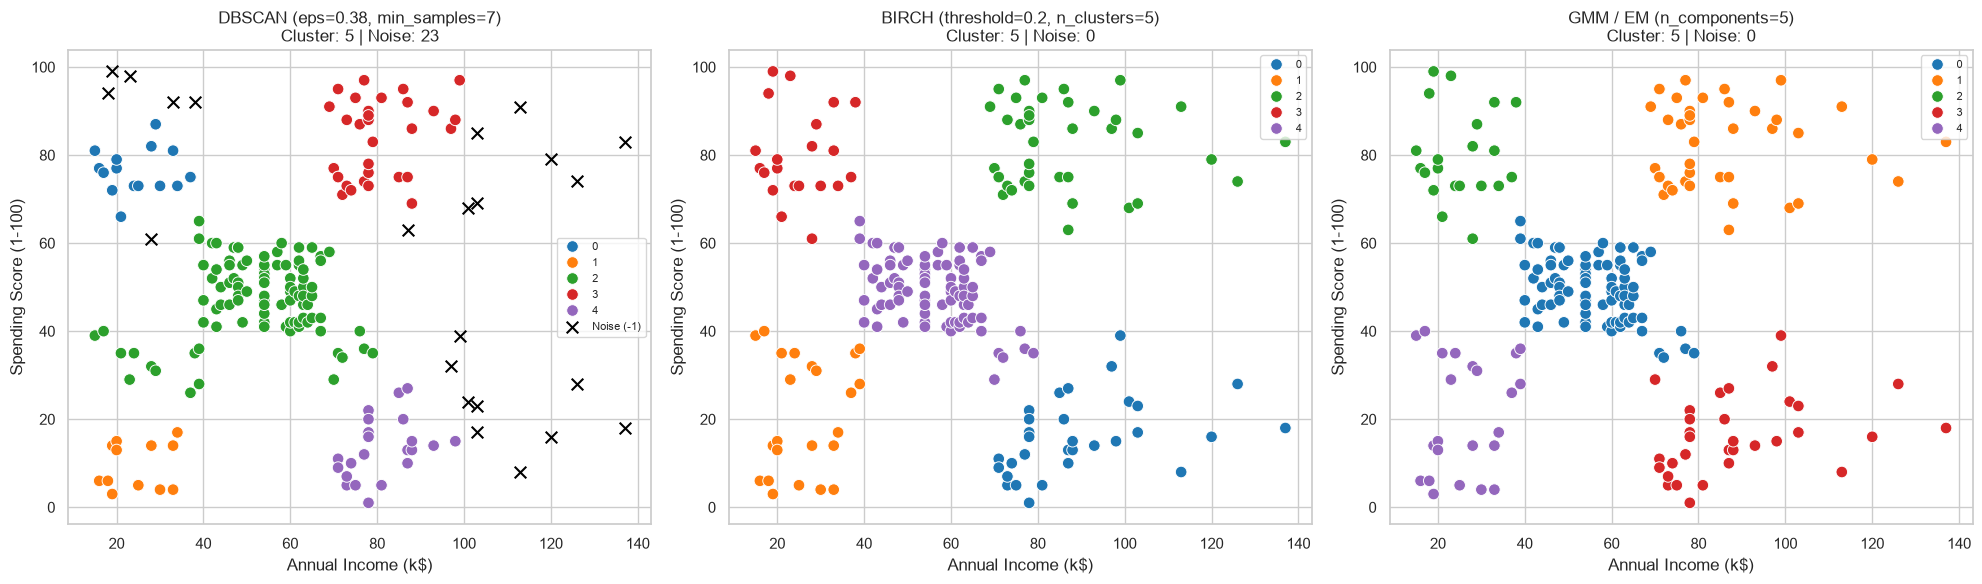

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Plot DBSCAN Terbaik
mask_ns = (labels_dbscan_best == -1)
sns.scatterplot(
    x=X.loc[~mask_ns, 'Annual Income (k$)'],
    y=X.loc[~mask_ns, 'Spending Score (1-100)'],
    hue=labels_dbscan_best[~mask_ns],
    palette='tab10', s=70, ax=axes[0], legend='full'
)
axes[0].scatter(
    X.loc[mask_ns, 'Annual Income (k$)'],
    X.loc[mask_ns, 'Spending Score (1-100)'],
    color='black', marker='x', s=70, label='Noise (-1)'
)
n_cl_db_best = len(set(labels_dbscan_best[~mask_ns]))
n_ns_db_best = int(np.sum(mask_ns))
axes[0].set_title(f'DBSCAN (eps=0.38, min_samples=7)\nCluster: {n_cl_db_best} | Noise: {n_ns_db_best}')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].legend(loc='best', fontsize=8)

# 2. Plot BIRCH Terbaik
sns.scatterplot(
    x=X['Annual Income (k$)'],
    y=X['Spending Score (1-100)'],
    hue=labels_birch_best,
    palette='tab10', s=70, ax=axes[1], legend='full'
)
axes[1].set_title('BIRCH (threshold=0.2, n_clusters=5)\nCluster: 5 | Noise: 0')
axes[1].set_xlabel('Annual Income (k$)')
axes[1].set_ylabel('Spending Score (1-100)')
axes[1].legend(loc='best', fontsize=8)

# 3. Plot GMM Terbaik
sns.scatterplot(
    x=X['Annual Income (k$)'],
    y=X['Spending Score (1-100)'],
    hue=labels_gmm,
    palette='tab10', s=70, ax=axes[2], legend='full'
)
axes[2].set_title('GMM / EM (n_components=5)\nCluster: 5 | Noise: 0')
axes[2].set_xlabel('Annual Income (k$)')
axes[2].set_ylabel('Spending Score (1-100)')
axes[2].legend(loc='best', fontsize=8)

plt.tight_layout()
plt.show()

In [25]:
def create_cluster_profile(X_orig, labels, model_title):
    df_temp = X_orig.copy()
    df_temp['Cluster'] = labels
    
    profile = df_temp.groupby('Cluster').agg(
        Jumlah_Anggota=('Annual Income (k$)', 'count'),
        Income_Mean=('Annual Income (k$)', 'mean'),
        Income_Median=('Annual Income (k$)', 'median'),
        Spending_Mean=('Spending Score (1-100)', 'mean'),
        Spending_Median=('Spending Score (1-100)', 'median')
    ).round(2)
    
    print(f"=== Profil Cluster: {model_title} ===")
    display(profile)

create_cluster_profile(X, labels_dbscan_best, "DBSCAN Terbaik (eps=0.38, min_samples=7) — Label -1 adalah Noise")
create_cluster_profile(X, labels_birch_best, "BIRCH Terbaik (threshold=0.2, n_clusters=5)")
create_cluster_profile(X, labels_gmm, "GMM / EM Terbaik (n_components=5)")

=== Profil Cluster: DBSCAN Terbaik (eps=0.38, min_samples=7) — Label -1 adalah Noise ===


,Jumlah_Anggota,Income_Mean,Income_Median,Spending_Mean,Spending_Median
Cluster,,,,,
-1,23,89.04,103.0,58.83,68.0
0,15,24.53,24.0,76.33,76.0
1,12,24.58,22.5,9.58,9.5
2,96,52.65,54.0,47.31,48.0
3,31,80.16,78.0,83.58,86.0
4,23,80.96,78.0,12.78,13.0


=== Profil Cluster: BIRCH Terbaik (threshold=0.2, n_clusters=5) ===


,Jumlah_Anggota,Income_Mean,Income_Median,Spending_Mean,Spending_Median
Cluster,,,,,
0,32,89.41,86.5,15.59,15.0
1,23,26.30,25.0,20.91,17.0
2,39,86.54,79.0,82.13,83.0
3,21,25.10,24.0,80.05,77.0
4,85,55.81,57.0,49.13,49.0


=== Profil Cluster: GMM / EM Terbaik (n_components=5) ===


,Jumlah_Anggota,Income_Mean,Income_Median,Spending_Mean,Spending_Median
Cluster,,,,,
0,84,55.64,55.5,49.37,49.5
1,39,86.54,79.0,82.13,83.0
2,21,25.10,24.0,80.05,77.0
3,33,88.82,86.0,16.00,15.0
4,23,26.30,25.0,20.91,17.0


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | | | |
| Dapat memberi label noise secara eksplisit? | | | |
| Parameter yang paling memengaruhi hasil | | | |
| Bentuk cluster yang dapat dimodelkan | | | |
| Kelebihan | | | |
| Kekurangan | | | |

### Ringkasan Perbandingan

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| **Perlu menentukan jumlah cluster di awal?** | **Tidak.** Jumlah cluster terbentuk otomatis dari kepadatan data. | **Opsional** (umumnya **Ya** melalui `n_clusters` untuk tahap *global clustering*). | **Ya**, wajib menentukan `n_components` sebelum model dilatih. |
| **Dapat memberi label noise secara eksplisit?** | **Ya**, titik di luar jangkauan kepadatan diberi label `-1` (*noise*). | **Tidak**, semua titik dimasukkan ke dalam subcluster/cluster terdekat. | **Tidak** secara langsung, tetapi dapat dideteksi dari probabilitas/densitas rendah. |
| **Parameter yang paling memengaruhi hasil** | `eps` (radius jarak) dan `min_samples` (kepadatan minimum). | `threshold` (radius subcluster CF-Tree) dan `n_clusters`. | `n_components` (jumlah Gaussian) dan `covariance_type`. |
| **Bentuk cluster yang dapat dimodelkan** | Bebas / *arbitrary shape* (mengikuti kontur kepadatan). | Cenderung membulat (*spherical*) pada subcluster daun CF-Tree. | Elips (*ellipsoidal*) dengan orientasi fleksibel sesuai matriks kovarians. |
| **Kelebihan** | Tahan terhadap *outlier* dan mampu menemukan bentuk cluster non-linier tanpa tahu jumlah $K$. | Sangat cepat dan hemat memori untuk dataset skala besar (*single scan* CF-Tree). | Memberikan probabilitas keanggotaan (*soft clustering*) dan sangat presisi pada distribusi elips. |
| **Kekurangan** | Sangat sensitif terhadap parameter dan kesulitan jika kepadatan antar cluster berbeda. | Sensitif terhadap nilai `threshold` dan kurang cocok untuk cluster berbentuk non-bulat. | Sensitif terhadap inisialisasi awal, mengasumsikan distribusi Gaussian, dan tidak punya label *noise* bawaan. |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

**Jawaban Analisis Keseluruhan:**

**1. Mengapa fitur perlu di-scaling?**
Sebelum di-*scaling*, `Annual Income` dan `Spending Score` memiliki variansi yang berbeda (simpangan baku 26.26 k$ berbanding 25.82). Standarisasi menjadikan mean=0 dan std=1. Tanpa ini, parameter jarak radius seperti `eps=0.38` pada DBSCAN atau `threshold=0.2` pada BIRCH akan menjadi lonjong mendominasi salah satu sumbu di ruang Euclidean.

**2. Efek perubahan parameter DBSCAN:**
Eksperimen membuktikan bahwa `eps` dan `min_samples` sangat sensitif. Mengurangi kepadatan dengan menaikkan `eps` ke 0.50 mengurangi jumlah *noise* hingga sisa 8 titik, namun fatal karena menyatukan 4 kelompok berbeda menjadi hanya 2 cluster raksasa. Mengetatkan `min_samples` ke 10 justru mendepak 129 dari 200 titik menjadi *noise*.

**3. Efek `threshold` dan `n_clusters` pada BIRCH:**
Ketika `threshold` di-set terlalu longgar (`0.5`), bentuk awal pohon terlalu kasar sehingga Silhouette Score akhirnya turun (0.4145). Saat kita haluskan `threshold` ke 0.2 (yang membentuk 39 subcluster daun sementara), tahap akhir peringkasan ke `n_clusters=5` berhasil memilah batas kelompok jauh lebih presisi (Silhouette naik drastis jadi 0.5538).

**4. Makna probabilitas keanggotaan GMM:**
Melalui matriks *predict_proba*, EM/GMM menilai sejauh mana sebuah observasi mewakili distribusi Gaussian tertentu. GMM tidak asal memotong wilayah; pelanggan di pinggir kelompok (misal indeks 124 dengan pendapatan 70 k$ dan skor belanja 29) dinilai memiliki kedekatan matematis 49.71% di Cluster 0 dan 50.29% di Cluster 3, menunjukkan posisinya yang benar-benar ada di zona transisi batas.

**5. Model mana yang paling mudah diinterpretasikan?**
**GMM (`n_components=5`)**. Plot *scatter* menunjukkan kelima segmen alami membentuk bola elips dengan kepadatan yang tak beraturan (kelompok tengah sangat rapat, kelompok sudut lebih renggang). GMM sangat presisi menelan kelima elips ini berkat `covariance_type='full'`, tanpa membuang puluhan pelanggan (23 - 47 titik) ke tong sampah sebagai label *noise* seperti yang dilakukan DBSCAN.

**6. Perbedaan Metrik Evaluasi:**
Terdapat divergensi (ketidaksamaan) antar metrik. *Silhouette Score* tertinggi diraih DBSCAN (`eps=0.35`) yakni **0.5708**, mengalahkan GMM (**0.5537**). **TETAPI**, ini angka yang bias karena DBSCAN membuang 47 titik renggang sebelum perhitungan, sehingga ia hanya mengevaluasi "kumpulan titik inti yang super padat". Saat metrik *Calinski-Harabasz* digunakan untuk mengevaluasi *seluruh 200 pelanggan tanpa sisa*, BIRCH dan GMM unggul mutlak dengan skor raksasa **244.41** dan **244.94**, jauh meninggalkan DBSCAN (216.75).

**7. Karakteristik Cluster Bisnis (Berdasarkan Median Eksperimen GMM/BIRCH):**
Berdasarkan agregasi kelompok GMM, kita mendapati penamaan yang jelas:
* **Cluster "Reguler / Rata-rata" (84 org):** Kelompok terbanyak di tengah grafik (Median Income: **55.5 k$**, Median Spend: **49.5**). Konsumen stabilitas mal.
* **Cluster "VIP / High Rollers" (39 org):** Median Income tinggi (**79 k$**) dan Spend super tinggi (**83.0**). Ini pangsa pasar kampanye produk *luxury*.
* **Cluster "Impulsif" (21 org):** Median Income pas-pasan (**24 k$**) namun Spend selangit (**77.0**). Cocok disasar dengan kartu kredit atau promo Buy 1 Get 1.
* **Cluster "Hemat / Frugal" (33 org):** Median Income meraksasa (**86 k$**) namun Spend sangat pelit (**15.0**). Market *niche* (potensi *untapped*)—mal ini mungkin kurang lengkap toko premiumnya.
* **Cluster "Budget / Sensibel" (23 org):** Median Income minim (**25 k$**) dan Spend juga seadanya (**17.0**).

**8. Keterbatasan ukuran dataset 2D kecil:**
Dengan hanya **200 pelanggan**, kepadatan di 4 cluster sudut terlalu "kurus", menyebabkan DBSCAN mengkategorikannya sebagai segerombolan *noise* yang terpisah-pisah. Menggunakan murni dua fitur tanpa demografi lain (`Age` & `Gender`) juga membutakan analisis—misalnya, kita tak tahu apakah "Cluster Frugal" yang kaya namun jarang belanja itu didominasi oleh golongan lansia yang tak butuh pakaian trendi.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

**Kesimpulan dan Saran:**

* **Algoritma yang memberikan hasil paling berguna:** **Gaussian Mixture Model (EM)** dengan `n_components=5` dan `covariance_type='full'` memberikan hasil paling optimal untuk dataset Mall Customers ini. Terbukti dari hasil metrik, GMM mencapai keseimbangan terbaik dengan **Silhouette Score 0.5537** dan **Calinski-Harabasz Score tertinggi (244.94)**, sekaligus menekan **nilai BIC ke titik terendah (1058.65)**. GMM juga berhasil mengelompokkan seluruh 200 pelanggan ke dalam 5 segmen bisnis yang jelas tanpa membuang satu pun data.
* **Parameter yang dipilih dan alasannya (Berdasarkan grid eksperimen):**
  * **GMM:** `n_components=5, covariance_type='full'` dipilih karena grafik eksperimen menunjukkan titik penurunan BIC yang tajam terhenti di $K=5$, bertepatan dengan Silhouette Score yang mencapai puncak tertingginya.
  * **BIRCH:** `threshold=0.2, n_clusters=5`. Berdasarkan eksperimen, `threshold=0.5` membuat hasil *clustering* kasar (Silhouette hanya `0.4145`). Dengan mengecilkan `threshold` ke `0.2`, pohon CF menyimpan detail lebih baik sehingga Silhouette Score naik signifikan menjadi `0.5538`.
  * **DBSCAN:** `eps=0.38, min_samples=7` (atau kisaran `eps=0.35`). Pada nilai ini, model berhasil membedakan 5 cluster utama (dengan skor Silhouette non-noise `0.54` - `0.57`), sambil melabeli sekitar 23-47 titik pinggiran yang renggang sebagai *noise* (-1). Jika parameter dibesarkan sedikit saja (misal `eps=0.5`), cluster menyatu hancur menjadi hanya 2 cluster.
* **Perbedaan utama (Temuan Praktis dari Data):**
  * **DBSCAN** pada dataset ini membuang sekitar 11%-23% pelanggan potensial sebagai *noise* karena bentuk antar-cluster memiliki kepadatan yang tidak seragam.
  * **BIRCH** sangat cepat, tapi kualitas klaster akhirnya (di tahap klastering global) sangat disetir oleh seberapa presisi pembentukan subcluster di tahap `threshold` awal.
  * **EM/GMM** adalah yang paling adaptif. Karena fitur `Annual Income` dan `Spending Score` membentuk kelompok elips dengan kepadatan berbeda, kovarians matriks pada GMM menangkap kontur elips tersebut dengan sempurna secara probabilistik.
* **Eksperimen lanjutan yang dapat dilakukan:**
  1. Menambahkan fitur `Age` (Usia) ke dalam model (clustering 3D) untuk melihat apakah cluster "Pendapatan Tinggi, Pengeluaran Rendah" didominasi oleh kelompok usia tertentu.
  2. Mencoba algoritma *HDBSCAN* yang secara teori lebih kebal terhadap perbedaan kepadatan klaster dibandingkan DBSCAN tradisional yang kesulitan di dataset mal ini.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)